We need to validate our data before running fastoma, as some are not working

In [ ]:
### Validation paths — inspect the actual FastOMA inputs

from pathlib import Path
from collections import Counter

import pandas as pd
from Bio import SeqIO
from ete4 import Tree

project_root = Path(
    "/home/saschabrown/evomics_projects/saschabrown/creating fasta files"
)

input_dir = project_root / "fastoma_input"
proteome_dir = input_dir / "proteome"
tree_file = input_dir / "species_tree.nwk"

validation_dir = project_root / "reports" / "input_validation"
validation_dir.mkdir(parents=True, exist_ok=True)

assert proteome_dir.is_dir(), f"Missing folder: {proteome_dir}"
assert tree_file.is_file(), f"Missing tree: {tree_file}"

print("FASTA folder:", proteome_dir)
print("Species tree:", tree_file)
print("Validation reports:", validation_dir)

Count the number of files

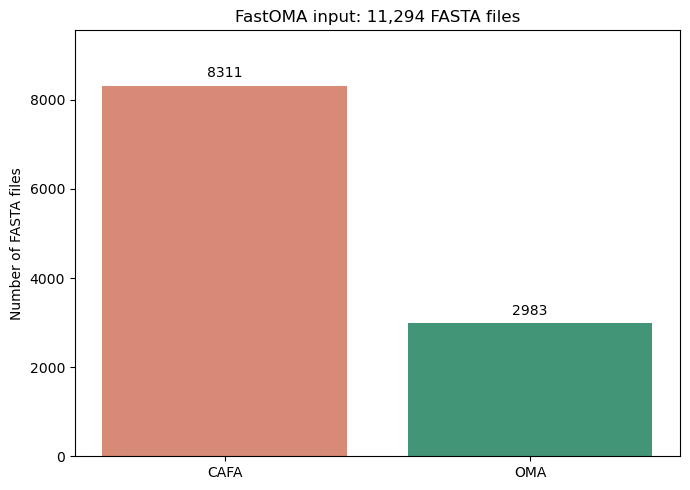

CAFA FASTAs: 8,311
OMA FASTAs:  2,983
Total:       11,294


In [3]:
### Plot the number of input FASTA files

import matplotlib.pyplot as plt

fasta_files = sorted(
    filename
    for filename in proteome_dir.iterdir()
    if filename.is_file()
    and filename.suffix.lower() in {".fa", ".fasta"}
)

# Naming convention in our prepared dataset:
# CAFA: 9606.fa; OMA: HUMAN.fa.
cafa_files = [filename for filename in fasta_files if filename.stem.isdigit()]
oma_files = [filename for filename in fasta_files if not filename.stem.isdigit()]

counts = [len(cafa_files), len(oma_files)]

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["CAFA", "OMA"],
    counts,
    color=["#D78A76", "#439578"],
)

ax.bar_label(bars, padding=4, fmt="%d")
ax.set_ylabel("Number of FASTA files")
ax.set_title(f"FastOMA input: {len(fasta_files):,} FASTA files")
ax.set_ylim(0, max(1, max(counts)) * 1.15)

plt.tight_layout()
plt.savefig(
    validation_dir / "input_fasta_file_counts.svg",
    bbox_inches="tight",
)
plt.show()

print(f"CAFA FASTAs: {len(cafa_files):,}")
print(f"OMA FASTAs:  {len(oma_files):,}")
print(f"Total:       {len(fasta_files):,}")

Now this shows that our files has acutally filtered some cafa species away as we wanted

In [5]:
### Count leaves in the FastOMA species tree

tree = Tree(str(tree_file), parser=1)
leaf_labels = [str(leaf.name) for leaf in tree.leaves()]

cafa_leaves = [label for label in leaf_labels if label.isdigit()]
oma_leaves = [label for label in leaf_labels if not label.isdigit()]

duplicates = {
    label: count
    for label, count in Counter(leaf_labels).items()
    if count > 1
}

print(f"Total tree leaves:       {len(leaf_labels):,}")
print(f"Unique leaf labels:      {len(set(leaf_labels)):,}")
print(f"CAFA leaves (numeric):   {len(cafa_leaves):,}")
print(f"OMA leaves (non-numeric): {len(oma_leaves):,}")
print("Duplicate leaf labels:", duplicates)

Total tree leaves:       11,294
Unique leaf labels:      11,294
CAFA leaves (numeric):   8,311
OMA leaves (non-numeric): 2,983
Duplicate leaf labels: {}


1)  Exact FASTA–tree matching
Compare filename stems with leaf labels. Equal counts alone are insufficient: the identifiers must match, with no missing or extra files.

In [6]:

### Check that FASTA filenames exactly match species-tree leaves

# Read the current files and tree again.
fasta_files = sorted(
    filename
    for filename in proteome_dir.iterdir()
    if filename.is_file()
    and filename.suffix.lower() in {".fa", ".fasta"}
)

tree = Tree(str(tree_file), parser=1)

fasta_labels = [filename.stem for filename in fasta_files]
leaf_labels = list(map(str, tree.leaf_names()))

fasta_ids = set(fasta_labels)
tree_ids = set(leaf_labels)

# Tree leaves without a corresponding FASTA.
missing_fastas = sorted(tree_ids - fasta_ids)

# FASTAs without a corresponding tree leaf.
extra_fastas = sorted(fasta_ids - tree_ids)

# Detect duplicate labels, including files such as 9606.fa and 9606.fasta.
duplicate_fastas = {
    label: count
    for label, count in Counter(fasta_labels).items()
    if count > 1
}
duplicate_leaves = {
    label: count
    for label, count in Counter(leaf_labels).items()
    if count > 1
}

print(f"FASTA files: {len(fasta_labels):,}")
print(f"Tree leaves: {len(leaf_labels):,}")
print("Tree leaves missing FASTAs:", missing_fastas)
print("FASTAs absent from tree:", extra_fastas)
print("Duplicate FASTA stems:", duplicate_fastas)
print("Duplicate tree labels:", duplicate_leaves)

# Save one row per identifier.
file_tree_check = pd.DataFrame(
    [
        {
            "identifier": label,
            "fasta_count": Counter(fasta_labels)[label],
            "tree_leaf_count": Counter(leaf_labels)[label],
        }
        for label in sorted(fasta_ids | tree_ids)
    ],
    columns=["identifier", "fasta_count", "tree_leaf_count"],
)

file_tree_check.to_csv(
    validation_dir / "fasta_tree_identifier_check.tsv",
    sep="\t",
    index=False,
)

assert fasta_files and leaf_labels, "The FASTA folder or tree has no entries."
assert not (
    missing_fastas
    or extra_fastas
    or duplicate_fastas
    or duplicate_leaves
), "FAILED: FASTA files and tree leaves do not match one-to-one."

print("\nPASSED: Every FASTA has exactly one matching tree leaf.")

FASTA files: 11,294
Tree leaves: 11,294
Tree leaves missing FASTAs: []
FASTAs absent from tree: []
Duplicate FASTA stems: {}
Duplicate tree labels: {}

PASSED: Every FASTA has exactly one matching tree leaf.


2 Tree structure
Check duplicate or empty leaf labels and ensure internal nodes have unique, nonempty names. Report multifurcations; do not automatically resolve them.

In [8]:
### Check species-tree structure and node names

from collections import Counter
from ete4 import Tree

tree = Tree(str(tree_file), parser=1)

leaves = list(tree.leaves())
internal_nodes = [
    node for node in tree.traverse()
    if not node.is_leaf
]

leaf_names = [
    "" if node.name is None else str(node.name)
    for node in leaves
]
internal_names = [
    "" if node.name is None else str(node.name)
    for node in internal_nodes
]

empty_leaves = sum(not name.strip() for name in leaf_names)
empty_internal = sum(not name.strip() for name in internal_names)

duplicate_leaves = {
    name: count
    for name, count in Counter(leaf_names).items()
    if name.strip() and count > 1
}
duplicate_internal = {
    name: count
    for name, count in Counter(internal_names).items()
    if name.strip() and count > 1
}

# Also detect an internal node using the same label as a leaf.
shared_names = sorted(
    {name for name in leaf_names if name.strip()}
    & {name for name in internal_names if name.strip()}
)

# Record the number of children for every internal node.
structure = pd.DataFrame(
    [
        {
            "node_name": node.name,
            "is_root": node is tree,
            "child_count": len(node.children),
        }
        for node in internal_nodes
    ],
    columns=["node_name", "is_root", "child_count"],
)

multifurcations = structure.loc[structure["child_count"] > 2]
unary_nodes = structure.loc[structure["child_count"] == 1]

print("Root name:", tree.name)
print(f"Leaves: {len(leaves):,}")
print(f"Internal nodes, including root: {len(internal_nodes):,}")
print("Empty leaf labels:", empty_leaves)
print("Empty internal-node labels:", empty_internal)
print("Duplicate leaf labels:", duplicate_leaves)
print("Duplicate internal-node labels:", duplicate_internal)
print("Names shared by leaves and internal nodes:", shared_names)
print("Multifurcations (>2 children):", len(multifurcations))
print("Unary nodes (1 child):", len(unary_nodes))

structure.to_csv(
    validation_dir / "species_tree_structure.tsv",
    sep="\t",
    index=False,
)

if not multifurcations.empty:
    print("\nFirst 10 multifurcations:")
    display(multifurcations.head(10))

if not unary_nodes.empty:
    print("\nFirst 10 unary nodes:")
    display(unary_nodes.head(10))

assert leaf_names, "Tree has no leaves."
assert not (
    empty_leaves
    or empty_internal
    or duplicate_leaves
    or duplicate_internal
    or shared_names
), "FAILED: Missing or conflicting tree-node labels."

print("\nPASSED: Tree-node labels are nonempty and unique.")

Root name: NODE_1
Leaves: 11,294
Internal nodes, including root: 4,240
Empty leaf labels: 0
Empty internal-node labels: 0
Duplicate leaf labels: {}
Duplicate internal-node labels: {}
Names shared by leaves and internal nodes: []
Multifurcations (>2 children): 2249
Unary nodes (1 child): 1

First 10 multifurcations:


,node_name,is_root,child_count
0,NODE_1,True,3
1,NODE_2,False,9
2,NODE_3,False,11
3,NODE_4,False,5
4,NODE_5,False,8
5,NODE_6,False,25
6,NODE_7,False,3
7,NODE_8,False,10
8,NODE_9,False,30
9,NODE_10,False,4



First 10 unary nodes:


,node_name,is_root,child_count
3009,NODE_3010,False,1



PASSED: Tree-node labels are nonempty and unique.


In [11]:
### Inspect the unary node without modifying the tree

node_names_file = (
    project_root / "data" / "prepared"
    / "irene_species_tree_node2name.tsv"
)

node_names = pd.read_csv(
    node_names_file,
    sep="\t",
    header=None,
    names=["node_label", "recorded_name"],
    dtype=str,
)

display(node_names.loc[node_names["node_label"] == "NODE_3010"])

for node in tree.traverse():
    if node.name == "NODE_3010":
        print("Node:", node.name)
        print("Parent:", node.up.name if node.up is not None else None)
        print("Direct children:", [child.name for child in node.children])
        print("Descendant leaves:", list(node.leaf_names())[:20])

,node_label,recorded_name
3009,NODE_3010,Sminthopsis fuliginosa


Node: NODE_3010
Parent: NODE_2879
Direct children: ['75753']
Descendant leaves: ['75753']


3 Every FASTA contains proteins and no empty sequences.

In [10]:
### Check FASTA contents: parsing, protein counts, and empty sequences

from Bio import SeqIO
import pandas as pd

input_files = sorted(
    filename
    for filename in proteome_dir.iterdir()
    if filename.is_file()
)

fasta_files = [
    filename
    for filename in input_files
    if filename.suffix in {".fa", ".fasta"}
]

unexpected_files = [
    filename.name
    for filename in input_files
    if filename.suffix not in {".fa", ".fasta"}
]

rows = []
empty_sequence_rows = []

for filename in fasta_files:
    protein_count = 0
    empty_count = 0
    parse_error = ""

    try:
        with filename.open() as handle:
            for record in SeqIO.parse(handle, "fasta"):
                protein_count += 1

                if len(record.seq) == 0:
                    empty_count += 1
                    empty_sequence_rows.append({
                        "filename": filename.name,
                        "species_label": filename.stem,
                        "protein_id": record.id,
                    })

    except Exception as error:
        parse_error = f"{type(error).__name__}: {error}"

    rows.append({
        "filename": filename.name,
        "species_label": filename.stem,
        "source": "CAFA" if filename.stem.isdigit() else "OMA",
        "protein_count": protein_count,
        "empty_sequence_count": empty_count,
        "parse_error": parse_error,
        "passed": (
            not parse_error
            and protein_count > 0
            and empty_count == 0
        ),
    })

fasta_content_check = pd.DataFrame(
    rows,
    columns=[
        "filename",
        "species_label",
        "source",
        "protein_count",
        "empty_sequence_count",
        "parse_error",
        "passed",
    ],
)

empty_sequences = pd.DataFrame(
    empty_sequence_rows,
    columns=["filename", "species_label", "protein_id"],
)

# Save reports, including failures.
fasta_content_check.to_csv(
    validation_dir / "fasta_content_check.tsv",
    sep="\t",
    index=False,
)
empty_sequences.to_csv(
    validation_dir / "empty_sequences.tsv",
    sep="\t",
    index=False,
)
pd.DataFrame({"filename": unexpected_files}).to_csv(
    validation_dir / "unexpected_input_files.tsv",
    sep="\t",
    index=False,
)

parsed = fasta_content_check["parse_error"].eq("")
failed = fasta_content_check.loc[
    fasta_content_check["passed"].eq(False)
]

print("FASTA files inspected:", len(fasta_content_check))
print("Files with parsing errors:", int((~parsed).sum()))
print(
    "Parsed files containing zero proteins:",
    int((parsed & fasta_content_check["protein_count"].eq(0)).sum()),
)
print("Empty sequences found:", len(empty_sequences))
print(
    "Parsed files with 1–2 proteins (allowed):",
    int((
        parsed
        & fasta_content_check["protein_count"].between(1, 2)
    ).sum()),
)
print("Unexpected non-FASTA files:", unexpected_files)

if not failed.empty:
    display(failed)

if not empty_sequences.empty:
    display(empty_sequences.head(20))

assert fasta_files, "No .fa or .fasta files found."
assert failed.empty, "FAILED: Some FASTAs are unreadable or contain empty inputs."

if unexpected_files:
    print("\nWARNING: Review the unexpected files listed above.")

print("\nPASSED: All FASTAs parsed and contain nonempty sequences.")

FASTA files inspected: 11294
Files with parsing errors: 0
Parsed files containing zero proteins: 0
Empty sequences found: 0
Parsed files with 1–2 proteins (allowed): 5206
Unexpected non-FASTA files: []

PASSED: All FASTAs parsed and contain nonempty sequences.


4 Protein IDs are unique within each file and no longer than 60 characters.

In [14]:
### 4. Check protein identifiers in every FASTA

from collections import Counter
from Bio import SeqIO
import pandas as pd

fasta_files = sorted(
    filename
    for filename in proteome_dir.iterdir()
    if filename.is_file()
    and filename.suffix.lower() in {".fa", ".fasta"}
)

summary_rows = []
issue_rows = []

for filename in fasta_files:
    id_counts = Counter()
    parse_error = ""

    try:
        with filename.open() as handle:
            for record in SeqIO.parse(handle, "fasta"):
                id_counts[record.id] += 1

    except Exception as error:
        parse_error = f"{type(error).__name__}: {error}"

    duplicates = {
        protein_id: count
        for protein_id, count in id_counts.items()
        if count > 1
    }

    long_ids = [
        protein_id for protein_id in id_counts
        if len(protein_id) > 60
    ]

    empty_id_count = id_counts.get("", 0)

    for protein_id, count in id_counts.items():
        reasons = []

        if not protein_id:
            reasons.append("empty_id")
        if count > 1:
            reasons.append("duplicate_id_within_file")
        if len(protein_id) > 60:
            reasons.append("id_longer_than_60_characters")

        if reasons:
            issue_rows.append({
                "filename": filename.name,
                "species_label": filename.stem,
                "protein_id": protein_id,
                "id_length": len(protein_id),
                "occurrences": count,
                "issues": ";".join(reasons),
            })

    summary_rows.append({
        "filename": filename.name,
        "species_label": filename.stem,
        "protein_count": sum(id_counts.values()),
        "unique_id_count": len(id_counts),
        "duplicate_id_count": len(duplicates),
        "long_id_count": len(long_ids),
        "empty_id_count": empty_id_count,
        "parse_error": parse_error,
        "passed": (
            not parse_error
            and not duplicates
            and not long_ids
            and empty_id_count == 0
        ),
    })

id_summary = pd.DataFrame(
    summary_rows,
    columns=[
        "filename", "species_label", "protein_count",
        "unique_id_count", "duplicate_id_count", "long_id_count",
        "empty_id_count", "parse_error", "passed",
    ],
)

id_issues = pd.DataFrame(
    issue_rows,
    columns=[
        "filename", "species_label", "protein_id",
        "id_length", "occurrences", "issues",
    ],
)

id_summary.to_csv(
    validation_dir / "protein_id_validation_summary.tsv",
    sep="\t",
    index=False,
)

id_issues.to_csv(
    validation_dir / "protein_id_issues.tsv",
    sep="\t",
    index=False,
)

failed = id_summary.loc[id_summary["passed"].eq(False)]

print("FASTA files inspected:", len(id_summary))
print("Files failing ID/parsing checks:", len(failed))
print("Distinct problematic IDs per file:", len(id_issues))

if not failed.empty:
    display(failed)

if not id_issues.empty:
    display(id_issues.head(30))

assert fasta_files, "No FASTA files found."
assert failed.empty, "FAILED: Inspect the protein ID reports."

print("\nPASSED: IDs are nonempty, unique within each file, and ≤60 characters.")

FASTA files inspected: 11294
Files failing ID/parsing checks: 0
Distinct problematic IDs per file: 0

PASSED: IDs are nonempty, unique within each file, and ≤60 characters.


5 CAFA sequences are ≥10 amino acids.

In [15]:
### 5. Verify that all CAFA proteins are at least 10 amino acids

from Bio import SeqIO
import pandas as pd

minimum_length = 10

cafa_files = sorted(
    filename
    for filename in proteome_dir.iterdir()
    if filename.is_file()
    and filename.suffix.lower() in {".fa", ".fasta"}
    and filename.stem.isdigit()
)

summary_rows = []
short_protein_rows = []

for filename in cafa_files:
    protein_count = 0
    short_count = 0
    shortest_length = None
    parse_error = ""

    try:
        with filename.open() as handle:
            for record in SeqIO.parse(handle, "fasta"):
                length = len(record.seq)
                protein_count += 1

                shortest_length = (
                    length
                    if shortest_length is None
                    else min(shortest_length, length)
                )

                if length < minimum_length:
                    short_count += 1
                    short_protein_rows.append({
                        "filename": filename.name,
                        "ncbi_taxid": filename.stem,
                        "protein_id": record.id,
                        "length_aa": length,
                    })

    except Exception as error:
        parse_error = f"{type(error).__name__}: {error}"

    summary_rows.append({
        "filename": filename.name,
        "ncbi_taxid": filename.stem,
        "protein_count": protein_count,
        "shortest_length_aa": shortest_length,
        "proteins_below_10aa": short_count,
        "parse_error": parse_error,
        "passed": (
            not parse_error
            and protein_count > 0
            and short_count == 0
        ),
    })

length_summary = pd.DataFrame(
    summary_rows,
    columns=[
        "filename", "ncbi_taxid", "protein_count",
        "shortest_length_aa", "proteins_below_10aa",
        "parse_error", "passed",
    ],
)

short_proteins = pd.DataFrame(
    short_protein_rows,
    columns=["filename", "ncbi_taxid", "protein_id", "length_aa"],
)

length_summary.to_csv(
    validation_dir / "cafa_min10_length_validation.tsv",
    sep="\t",
    index=False,
)

short_proteins.to_csv(
    validation_dir / "cafa_proteins_below_10aa.tsv",
    sep="\t",
    index=False,
)

failed = length_summary.loc[length_summary["passed"].eq(False)]

print("CAFA FASTAs inspected:", len(length_summary))
print("Protein records read:", int(length_summary["protein_count"].sum()))
print("Proteins shorter than 10 aa:", len(short_proteins))
print("Files failing validation:", len(failed))

if not failed.empty:
    display(failed)

if not short_proteins.empty:
    display(short_proteins.head(30))

assert cafa_files, "No numeric-named CAFA FASTAs found."
assert failed.empty, "FAILED: Check the CAFA length-validation reports."

print("\nPASSED: All CAFA FASTAs contain proteins, and every sequence is ≥10 aa.")

CAFA FASTAs inspected: 8311
Protein records read: 222074
Proteins shorter than 15 aa: 0
Files failing validation: 0

PASSED: All CAFA FASTAs contain proteins, and every sequence is ≥15 aa.
